# Áp dụng benchmark ATC (Cunha et al., 2025) cho phân loại văn bản tiếng Việt

Bài báo *"A thorough benchmark of automatic text classification: From traditional approaches to large language models"* so sánh **3 nhóm phương pháp** trên hai tiêu chí **hiệu quả (Macro-F1)** và **chi phí (thời gian)**:

| Nhóm trong bài báo | Đại diện trong bài báo | Áp dụng cho tiếng Việt ở notebook này |
|---|---|---|
| Traditional | TF-IDF + SVM / LR / RF | TF-IDF + LinearSVM / LogisticRegression / RandomForest |
| SLM (small LM) | RoBERTa, BERT, BART, XLNet | PhoBERT, viBERT, XLM-RoBERTa (đã chạy ở notebook trước) |
| LLM | LLaMA, Mistral, DeepSeek... (QLoRA 4-bit) | Tùy chọn: LLM nhỏ + QLoRA (Qwen2.5-1.5B) vì Colab T4 không đủ sức chạy 7-8B |

Quy trình bám theo bài báo:
1. Metric chính là **Macro-F1** (vì dữ liệu lệch lớp), kèm Accuracy.
2. Traditional: TF-IDF, grid search siêu tham số `C` (SVM, LR), `n_estimators`/`max_features` (RF) theo đúng lưới của bài báo.
3. Đo **tổng thời gian** (train + dự đoán test) của từng mô hình.
4. Biểu đồ **trade-off hiệu quả - chi phí** (log2 thời gian vs Macro-F1, có đường trung vị chia 4 góc phần tư).
5. Kết luận theo 3 khuyến nghị của bài báo: LLM (hiệu quả tối đa), Traditional (rẻ nhất), SLM (cân bằng).

**Khác biệt so với bài báo (cần nêu trong phần hạn chế):** bài báo dùng 10-fold cross-validation và kiểm định t-test; ở đây dùng sẵn train/validation/test của UIT-VSFC và thay bằng bootstrap CI trên test.

## 1. Cài đặt và import

In [ ]:
!pip install -q "datasets<4.0" transformers scikit-learn accelerate pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

## 2. Dữ liệu (Vietnamese Students' Feedback - 3 lớp cảm xúc)

In [ ]:
ds = load_dataset("uitnlp/vietnamese_students_feedback")
TEXT, LABEL = "sentence", "sentiment"
LABEL_NAMES = {0: "negative", 1: "neutral", 2: "positive"}

Xtr, ytr = list(ds["train"][TEXT]), np.array(ds["train"][LABEL])
Xva, yva = list(ds["validation"][TEXT]), np.array(ds["validation"][LABEL])
Xte, yte = list(ds["test"][TEXT]), np.array(ds["test"][LABEL])

print("train/val/test:", len(Xtr), len(Xva), len(Xte))
dist = pd.DataFrame({
    "train": pd.Series(ytr).value_counts(normalize=True).sort_index(),
    "test": pd.Series(yte).value_counts(normalize=True).sort_index()}).round(3)
dist.index = [LABEL_NAMES[i] for i in dist.index]
print("Phân bố lớp (độ lệch lớp là lý do dùng Macro-F1):")
dist

README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

vietnamese_students_feedback.py:   0%|          | 0.00/4.97k [00:00<?, ?B/s]

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

default/validation/0000.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

Generating validation split:   0%|          | 0/1583 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3166 [00:00<?, ? examples/s]

train/val/test: 11426 1583 3166
Phân bố lớp (độ lệch lớp là lý do dùng Macro-F1):


,train,test
negative,0.466,0.445
neutral,0.040,0.053
positive,0.494,0.502


## 3. Nhóm Traditional: TF-IDF + SVM / LR / RF

- Biểu diễn: TF-IDF (bài báo chọn TF-IDF vì đơn giản và hiệu quả). Dùng thêm unigram + bigram vì tiếng Việt có nhiều từ ghép gồm 2 âm tiết.
- Chọn siêu tham số bằng **Macro-F1 trên tập validation** với lưới giống bài báo.
- "Thời gian" của mỗi mô hình = vector hóa TF-IDF + fit trên train + dự đoán test, **không tính thời gian tune**, để so sánh công bằng với thời gian fine-tune của SLM. Thời gian tune được báo riêng.

In [ ]:
def macro_f1(y, p): return f1_score(y, p, average="macro")

def make_vec():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Lưới siêu tham số lấy theo bài báo (Section 2.3)
GRIDS = {
    "LinearSVM": (lambda C: LinearSVC(C=C, max_iter=5000, random_state=SEED),
                  [{"C": c} for c in [0.125, 0.5, 1, 2, 8, 32, 128, 512, 2048, 8192]]),
    "LogReg":    (lambda C: LogisticRegression(C=C, max_iter=2000),
                  [{"C": c} for c in [0.001, 0.01, 0.1, 1]]),
    "RandomForest": (lambda n, f: RandomForestClassifier(n_estimators=n, max_features=f, n_jobs=-1, random_state=SEED),
                     [{"n": n, "f": f} for n in [50, 100, 200] for f in [0.08, 0.15, 0.30]]),
}

# 1) Tune trên validation
vec = make_vec()
Ttr = vec.fit_transform(Xtr); Tva = vec.transform(Xva)
best_params, tune_time = {}, {}
for name, (factory, grid) in GRIDS.items():
    t0, best = time.time(), (-1, None)
    for params in grid:
        s = macro_f1(yva, factory(**params).fit(Ttr, ytr).predict(Tva))
        if s > best[0]: best = (s, params)
    tune_time[name] = round(time.time() - t0)
    best_params[name] = best[1]
    print(f"{name:13s} best={best[1]}  val Macro-F1={best[0]:.4f}  (tune {tune_time[name]}s)")

LinearSVM     best={'C': 2}  val Macro-F1=0.7428  (tune 52s)
LogReg        best={'C': 1}  val Macro-F1=0.6754  (tune 4s)
RandomForest  best={'n': 200, 'f': 0.3}  val Macro-F1=0.7676  (tune 329s)


In [ ]:
# 2) Chạy lại với tham số tốt nhất, đo thời gian (TF-IDF + fit + predict test) và đánh giá trên test
results, preds = [], {}
for name, (factory, _) in GRIDS.items():
    t0 = time.time()
    v = make_vec()
    A = v.fit_transform(Xtr); B = v.transform(Xte)
    clf = factory(**best_params[name]).fit(A, ytr)
    p = clf.predict(B)
    total = time.time() - t0
    preds[name] = p
    results.append({"Group": "Traditional", "Model": name,
                    "Accuracy": round(accuracy_score(yte, p), 4),
                    "F1-macro": round(macro_f1(yte, p), 4),
                    "Time (s)": round(total, 1)})
    print(results[-1])

{'Group': 'Traditional', 'Model': 'LinearSVM', 'Accuracy': 0.8945, 'F1-macro': 0.7154, 'Time (s)': 0.5}
{'Group': 'Traditional', 'Model': 'LogReg', 'Accuracy': 0.891, 'F1-macro': 0.6529, 'Time (s)': 1.1}
{'Group': 'Traditional', 'Model': 'RandomForest', 'Accuracy': 0.8825, 'F1-macro': 0.7194, 'Time (s)': 92.3}


## 4. Nhóm SLM: kết quả PhoBERT / viBERT / XLM-RoBERTa

Điền kết quả bạn đã chạy ở notebook `compare_models` (thời gian = thời gian train 3 epoch trên Colab T4). Nếu muốn có **khoảng tin cậy** cho cả SLM, chạy cell tùy chọn ở mục 4b để lưu dự đoán.

In [ ]:
slm_results = [
    {"Group": "SLM", "Model": "PhoBERT",     "Accuracy": 0.9324, "F1-macro": 0.8182, "Time (s)": 810},
    {"Group": "SLM", "Model": "viBERT",      "Accuracy": 0.9169, "F1-macro": 0.7734, "Time (s)": 816},
    {"Group": "SLM", "Model": "XLM-RoBERTa", "Accuracy": 0.9334, "F1-macro": 0.8089, "Time (s)": 875},
]
results += slm_results

### 4b. (Tùy chọn, ~40 phút GPU) Chạy lại SLM và lưu dự đoán để tính khoảng tin cậy

In [ ]:
RUN_SLM = False   # đổi thành True nếu muốn chạy lại để có dự đoán

if RUN_SLM:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
    EPOCHS, BATCH, MAXLEN, LR = 3, 16, 128, 2e-5
    slm_preds = {}

    def run_slm(name, ckpt):
        tok = AutoTokenizer.from_pretrained(ckpt)
        def encode(b):
            e = tok(b[TEXT], truncation=True, padding="max_length", max_length=MAXLEN)
            e["labels"] = b[LABEL]; return e
        data = ds.map(encode, batched=True)
        data.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
        model = AutoModelForSequenceClassification.from_pretrained(ckpt, num_labels=3)
        args = TrainingArguments(output_dir=f"out_{name}", num_train_epochs=EPOCHS,
            per_device_train_batch_size=BATCH, per_device_eval_batch_size=64, learning_rate=LR,
            save_strategy="no", report_to="none", logging_steps=100, seed=SEED)
        tr = Trainer(model=model, args=args, train_dataset=data["train"])
        t0 = time.time(); tr.train(); t_train = time.time() - t0
        t0 = time.time(); out = tr.predict(data["test"]); t_pred = time.time() - t0
        p = out.predictions.argmax(-1)
        slm_preds[name] = p
        np.save(f"pred_{name}.npy", p)
        return {"Group": "SLM", "Model": name, "Accuracy": round(accuracy_score(yte, p), 4),
                "F1-macro": round(macro_f1(yte, p), 4), "Time (s)": round(t_train + t_pred, 1)}

    new = [run_slm("PhoBERT", "vinai/phobert-base"),
           run_slm("viBERT", "FPTAI/vibert-base-cased"),
           run_slm("XLM-RoBERTa", "xlm-roberta-base")]
    results = [r for r in results if r["Group"] != "SLM"] + new
    preds.update(slm_preds)

## 5. (Tùy chọn) Nhóm LLM: LLM nhỏ + QLoRA 4-bit

Bài báo fine-tune LLaMA 3.1 8B, Mistral 7B... bằng **QLoRA + 4-bit** (lr 2e-4, batch 4, max_len 256). Một GPU T4 16GB không đủ thời gian cho mô hình 7-8B trên 11k mẫu, nên ở đây dùng **Qwen2.5-1.5B** (đa ngôn ngữ, có tiếng Việt) và 1 epoch. Kết quả này đại diện cho hướng LLM nhưng **không tương đương** LLM 7-8B của bài báo, cần nêu rõ trong báo cáo.

In [ ]:
RUN_LLM = False   # đổi thành True để chạy (cần GPU, ~1-2 giờ trên T4)
LLM_CKPT = "Qwen/Qwen2.5-1.5B"

if RUN_LLM:
    !pip install -q peft bitsandbytes
    import torch
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, BitsAndBytesConfig,
                              TrainingArguments, Trainer, DataCollatorWithPadding)
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

    tok = AutoTokenizer.from_pretrained(LLM_CKPT)
    if tok.pad_token is None: tok.pad_token = tok.eos_token

    def enc(b):
        e = tok(b[TEXT], truncation=True, max_length=256)
        e["labels"] = b[LABEL]; return e
    cols = ds["train"].column_names
    data = ds.map(enc, batched=True, remove_columns=cols)

    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16)
    model = AutoModelForSequenceClassification.from_pretrained(
        LLM_CKPT, num_labels=3, quantization_config=bnb, device_map={"": 0})
    model.config.pad_token_id = tok.pad_token_id
    model = prepare_model_for_kbit_training(model)
    model = get_peft_model(model, LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, task_type="SEQ_CLS",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]))

    args = TrainingArguments(output_dir="out_llm", num_train_epochs=1,
        per_device_train_batch_size=8, per_device_eval_batch_size=16, learning_rate=2e-4,
        fp16=True, save_strategy="no", report_to="none", logging_steps=100, seed=SEED)
    tr = Trainer(model=model, args=args, train_dataset=data["train"],
                 data_collator=DataCollatorWithPadding(tok))
    t0 = time.time(); tr.train(); t_train = time.time() - t0
    t0 = time.time(); out = tr.predict(data["test"]); t_pred = time.time() - t0
    p = out.predictions.argmax(-1)
    preds["Qwen2.5-1.5B+QLoRA"] = p
    results.append({"Group": "LLM", "Model": "Qwen2.5-1.5B+QLoRA",
                    "Accuracy": round(accuracy_score(yte, p), 4),
                    "F1-macro": round(macro_f1(yte, p), 4),
                    "Time (s)": round(t_train + t_pred, 1)})
    print(results[-1])

## 6. Bảng so sánh (RQ1: hiệu quả, RQ2: chi phí)

- **Gain** = Macro-F1 tăng/giảm so với mô hình traditional tốt nhất.
- **Cost ratio** = thời gian của mô hình / thời gian của mô hình traditional tốt nhất (tương tự "590x" và "8.5x" trong bài báo).

In [ ]:
df = pd.DataFrame(results)
base = df[df.Group == "Traditional"].sort_values("F1-macro", ascending=False).iloc[0]
df["Gain F1 vs best trad. (pts)"] = ((df["F1-macro"] - base["F1-macro"]) * 100).round(2)
df["Cost ratio vs best trad. (x)"] = (df["Time (s)"] / max(base["Time (s)"], 0.1)).round(1)
print(f"Baseline traditional tốt nhất: {base['Model']} (F1-macro={base['F1-macro']}, {base['Time (s)']}s)")
df = df.sort_values("F1-macro", ascending=False).reset_index(drop=True)
df.to_csv("results_all.csv", index=False)
df

Baseline traditional tốt nhất: RandomForest (F1-macro=0.7194, 92.3s)


,Group,Model,Accuracy,F1-macro,Time (s),Gain F1 vs best trad. (pts),Cost ratio vs best trad. (x)
0,SLM,PhoBERT,0.9324,0.8182,810.0,9.88,8.8
1,SLM,XLM-RoBERTa,0.9334,0.8089,875.0,8.95,9.5
2,SLM,viBERT,0.9169,0.7734,816.0,5.40,8.8
3,Traditional,RandomForest,0.8825,0.7194,92.3,0.00,1.0
4,Traditional,LinearSVM,0.8945,0.7154,0.5,-0.40,0.0
5,Traditional,LogReg,0.8910,0.6529,1.1,-6.65,0.0


### Khoảng tin cậy 95% (bootstrap trên test) và so sánh cặp

Bài báo dùng t-test trên 10 fold; ở đây chỉ có 1 lần chạy nên dùng bootstrap để biết chênh lệch nhỏ có ý nghĩa hay chỉ là nhiễu. Chỉ tính được cho mô hình có dự đoán (Traditional, và SLM/LLM nếu đã chạy mục 4b/5).

In [ ]:
def bootstrap_ci(y, p, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), (n, len(y)))
    s = np.array([macro_f1(y[i], p[i]) for i in idx])
    return np.percentile(s, [2.5, 97.5])

def paired_bootstrap(y, p1, p2, n=1000, seed=SEED):
    """Xác suất mô hình 1 có Macro-F1 cao hơn mô hình 2 trên các mẫu bootstrap."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), (n, len(y)))
    d = np.array([macro_f1(y[i], p1[i]) - macro_f1(y[i], p2[i]) for i in idx])
    return (d > 0).mean(), np.percentile(d, [2.5, 97.5])

rows = []
for name, p in preds.items():
    lo, hi = bootstrap_ci(yte, p)
    rows.append({"Model": name, "F1-macro": round(macro_f1(yte, p), 4), "CI 95%": f"[{lo:.4f}, {hi:.4f}]"})
pd.DataFrame(rows)

,Model,F1-macro,CI 95%
0,LinearSVM,0.7154,"[0.6872, 0.7416]"
1,LogReg,0.6529,"[0.6302, 0.6781]"
2,RandomForest,0.7194,"[0.6928, 0.7480]"


In [ ]:
names = list(preds)
if len(names) >= 2:
    ranked = sorted(names, key=lambda n: -macro_f1(yte, preds[n]))
    a, b = ranked[0], ranked[1]
    prob, ci = paired_bootstrap(yte, preds[a], preds[b])
    print(f"{a} vs {b}: P({a} > {b}) = {prob:.2f}, CI95 chênh lệch Macro-F1 = [{ci[0]:.4f}, {ci[1]:.4f}]")
    print("=> Nếu CI chứa 0 thì chưa đủ bằng chứng để nói hai mô hình khác nhau.")

RandomForest vs LinearSVM: P(RandomForest > LinearSVM) = 0.62, CI95 chênh lệch Macro-F1 = [-0.0233, 0.0327]
=> Nếu CI chứa 0 thì chưa đủ bằng chứng để nói hai mô hình khác nhau.


### Phân tích theo lớp (lý do Macro-F1 thấp hơn Accuracy)

In [ ]:
best_trad = df[df.Group == "Traditional"].iloc[0]["Model"]
print("Mô hình traditional tốt nhất:", best_trad)
print(classification_report(yte, preds[best_trad], target_names=[LABEL_NAMES[i] for i in range(3)], digits=4))

Mô hình traditional tốt nhất: RandomForest
              precision    recall  f1-score   support

    negative     0.8804    0.9191    0.8993      1409
     neutral     0.5513    0.2575    0.3510       167
    positive     0.9004    0.9157    0.9080      1590

    accuracy                         0.8825      3166
   macro avg     0.7774    0.6974    0.7194      3166
weighted avg     0.8731    0.8825    0.8748      3166



## 7. Biểu đồ trade-off hiệu quả - chi phí (tương tự Figure 2 của bài báo)

Trục x: log2(thời gian, giây); trục y: Macro-F1; đường nét đứt là **trung vị**. Càng **lên cao và sang trái** càng tốt (góc trên-trái: vừa hiệu quả vừa nhanh).

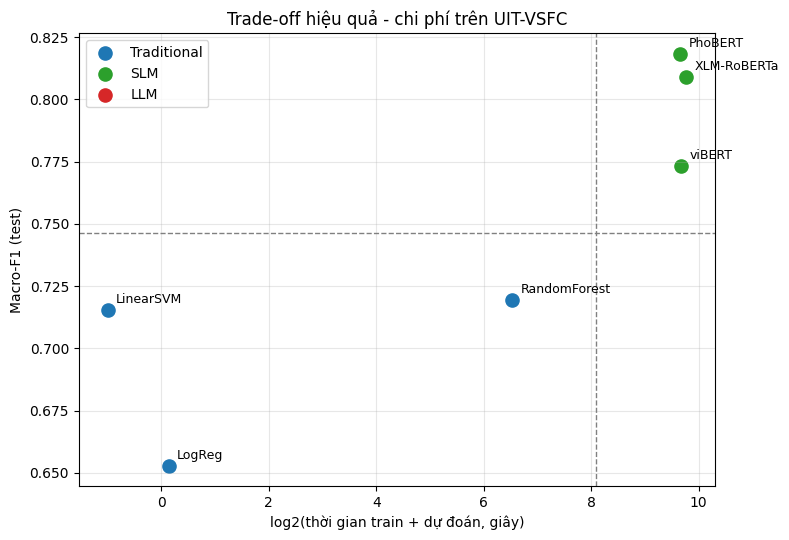

In [ ]:
colors = {"Traditional": "tab:blue", "SLM": "tab:green", "LLM": "tab:red"}
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.log2(df["Time (s)"].clip(lower=0.1)); y = df["F1-macro"]
for g, c in colors.items():
    m = df.Group == g
    ax.scatter(x[m], y[m], s=90, c=c, label=g)
for xi, yi, n in zip(x, y, df.Model):
    ax.annotate(n, (xi, yi), textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.axvline(np.median(x), ls="--", c="gray", lw=1); ax.axhline(np.median(y), ls="--", c="gray", lw=1)
ax.set_xlabel("log2(thời gian train + dự đoán, giây)"); ax.set_ylabel("Macro-F1 (test)")
ax.set_title("Trade-off hiệu quả - chi phí trên UIT-VSFC"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results_tradeoff.png", dpi=200); plt.show()

## 8. Kết luận mẫu (điền số sau khi chạy)

**RQ1 - hiệu quả:** so với bài báo (LLM > SLM > Traditional), kết quả trên tiếng Việt là: ... (nêu mô hình có Macro-F1 cao nhất, chênh lệch so với Traditional tốt nhất `Gain`, và kiểm tra khoảng tin cậy bootstrap có chứa 0 hay không).

**RQ2 - chi phí:** mô hình SLM chậm hơn Traditional khoảng `Cost ratio` lần (bài báo: SLM chậm hơn traditional ~14 lần, LLM chậm hơn ~590 lần).

**Khuyến nghị theo bài báo, áp dụng cho tiếng Việt:**
1. Cần hiệu quả tối đa và chịu được chi phí: LLM (fine-tune QLoRA).
2. Hạn chế tài nguyên: Traditional (TF-IDF + SVM/LR) cho kết quả hợp lý với chi phí thấp nhất.
3. Cân bằng: SLM như PhoBERT/XLM-RoBERTa (bài báo khuyến nghị RoBERTa).

**Hạn chế cần nêu:** 1 lần chạy/1 seed thay vì 10-fold; phần cứng khác nhau (Traditional chạy CPU, SLM/LLM chạy GPU T4) nên so sánh thời gian chỉ mang tính tương đối; LLM dùng mô hình nhỏ thay vì 7-8B; dữ liệu nhỏ (~16k câu) và lệch lớp nên lớp `neutral` làm Macro-F1 dao động mạnh.